# 14 · Where are the meninges? A gene-based answer from the Xenium EAE atlas

Our images (nuclei, Pu.1, Iba1) cannot separate meninges from subpial lesion (notebook 13). The RRMAP2 Xenium 5k
atlas of EAE spinal cord can: **157 sections**, CFA controls and every EAE phase, 5,000 genes and the raw
transcripts. Two gene layers mark the border:

* **meningeal fibroblast genes** – Slc47a1, Foxc2, Crabp2, Osr1, Slc13a4, Smoc2, Wnt6, Klf5, Fmod, Cdh1: chosen
  from the atlas as the genes detected in meningeal fibroblasts but rarely in any other cell (table below);
  Ptgds and the collagens are *not* specific here (Ptgds spreads into many cells; collagens are shared with the
  lesion fibroblasts);
* **glia limitans genes** – Aqp4 and Gfap: the astrocyte endfeet on the parenchymal side of the pia.

**Method** (`lesionseg/xenium_meninges.py`; `scripts/xenium_transcript_rasters.py` on the remote;
`scripts/xenium_meninges.py`):

1. All transcripts of a capture region binned at 5 µm. **Tissue** = transcript density above half the section's
   median (the edge at half maximum; a looser mask sat 15–20 µm outside the cells). **Depth** = distance to the
   tissue edge – the same definition the image pipeline uses on its own tissue mask.
2. Every tissue pixel is assigned to its nearest edge point; edge points are grouped into **50 µm stretches**.
3. Per stretch, 5 µm depth rings (3 pooled), the **pia** placed two ways with opposite biases:
   * **balance** – the run of rings from the surface where the meningeal share of transcripts beats the
     glia-limitans share (each scaled between the section's surface and deep levels) and is ≥ 10 % of the way to
     its surface level. Immune transcripts dilute the meningeal *share* in swollen meninges → leans "subpial".
   * **glia** – the run of rings from the surface where the glia-limitans *density* is below half its deep level
     (no astrocyte endfeet yet). Astrocyte loss in lesions → leans "meningeal".

   Stretches that never reach parenchyma (flaps, tears, oblique cuts) get no pia and are left out.
4. Atlas cells (curated cell types) are placed **above** (meninges) or **below** (parenchyma) the pia of their
   stretch.

Unit for comparisons: the section. Atlas cells ≠ our cells – the depth scales of the two datasets are not
calibrated against each other (both measure from a tissue edge, but from different masks).

In [1]:
import os, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
%config InlineBackend.figure_format = 'jpeg'   # image-heavy notebooks: keep files small
plt.rcParams["figure.dpi"] = 80
from lesionseg import report as R
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
RUN_DIR = "outputs/sdata"
runs = R.load_runs(RUN_DIR)
print("scenes:", [r.name for r in runs])

from lesionseg import xenium_meninges as X
OUT, WORK = Path("results/xenium_meninges"), Path("outputs/xenium_meninges")
sh = pd.read_csv("../ImmunoTransformer/docs/sample_sheet/sections.csv")
sh["group"] = np.where(sh.condition == "CONTROL", "CFA control", sh.phase)
prof_g = pd.read_csv(OUT / "depth_profiles.csv")
ab = pd.read_csv(OUT / "above_pia_by_depth.csv")
abs_ = pd.read_csv(OUT / "immune_above_pia_by_section.csv")
aba = pd.read_csv(OUT / "immune_above_pia_by_animal.csv")
pia = pd.read_parquet(WORK / "pia.parquet")
cov = pd.read_csv(OUT / "section_coverage.csv")
PH = [p for p in X.PHASES if p in set(sh.group)]
EAE = [g for g in PH if g != "CFA control"]
PCOL = dict(zip(PH, ["#898781", "#c3c2b7", "#eda100", "#e87ba4", "#3987e5", "#9085e9", "#199e70", "#0b6e4f"]))
BINS = ["(0, 10]", "(10, 20]", "(20, 30]", "(30, 50]", "(50, 80]", "(80, 150]"]
MID = dict(zip(BINS, [5, 15, 25, 40, 65, 115]))
print(f"{sh.section.nunique()} sections in the sheet · {pia.section.nunique()} with a pia · {len(pia):,} stretches")
print("share of a section's edge stretches with a pia (median, 5th pct):", cov.stretches_with_pia.median().round(2),
      cov.stretches_with_pia.quantile(.05).round(2))
sh.groupby("group").agg(sections=("section", "size"), animals=("animal", "nunique")).reindex(PH)

scenes: ['CML_1 scene 0', 'CML_2_rescan scene 0', 'CML_metal scene 0', 'CML_metal scene 1']
158 sections in the sheet · 157 with a pia · 29,776 stretches
share of a section's edge stretches with a pia (median, 5th pct): 0.69 0.51


,sections,animals
group,,
CFA control,17,8
pre-symptomatic,8,5
onset,21,9
peak,48,19
remission,26,9
late,12,4
early chronic (day 16),12,6
late chronic (day 30),14,7


## Which genes mark the meningeal fibroblasts (detection rate: fraction of cells with ≥ 1 transcript)

In [2]:
det = pd.read_csv(OUT / "fb_gene_detection.csv", index_col=0)
chosen = ["Slc47a1", "Foxc2", "Crabp2", "Osr1", "Slc13a4", "Smoc2", "Wnt6", "Klf5", "Fmod", "Cdh1"]
other = ["Ptgds", "Col1a1", "Col1a2", "Lum", "Igf2", "Aqp4", "Gfap", "Ptprc", "Cd74", "Mrc1"]
print("first 10 rows: the meningeal group; then for comparison")
det.loc[chosen + other].round(2)

first 10 rows: the meningeal group; then for comparison


,meningeal_fb,eae_associated_fb,perineural_fb,cam,vsmc,all_other,vs_other,vs_eae_fb
gene_symbol,,,,,,,,
Slc47a1,0.35,0.03,0.09,0.01,0.00,0.01,20.27,9.71
Foxc2,0.53,0.18,0.47,0.02,0.06,0.02,19.01,2.78
Crabp2,0.63,0.16,0.40,0.04,0.01,0.03,15.50,3.73
Osr1,0.41,0.19,0.20,0.02,0.01,0.02,14.29,2.08
Slc13a4,0.33,0.11,0.29,0.01,0.01,0.01,13.39,2.72
Smoc2,0.37,0.07,0.50,0.01,0.01,0.02,13.33,4.35
Wnt6,0.61,0.26,0.72,0.05,0.03,0.04,11.93,2.23
Klf5,0.62,0.25,0.84,0.05,0.05,0.05,10.04,2.40
Fmod,0.59,0.28,0.32,0.09,0.22,0.09,5.87,2.07


## Gene layers against depth (all sections of a phase pooled; per 1000 transcripts)

The meningeal genes peak in the outer 5–15 µm; the glia limitans dips there and rises from ~20–30 µm; immune
transcripts in EAE are highest at 15–40 µm – right where the two layers meet.

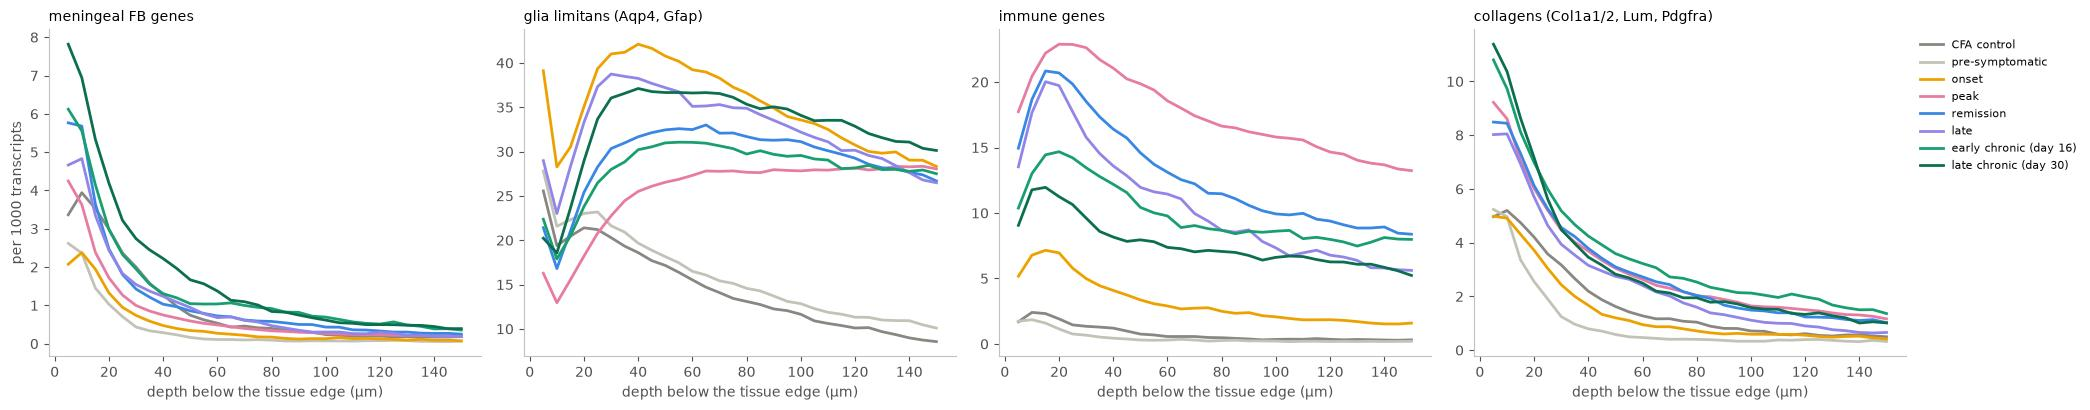

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), sharex=True)
for ax, k, t in zip(axes, ["meningeal", "glia_limitans", "immune", "collagen"],
                    ["meningeal FB genes", "glia limitans (Aqp4, Gfap)", "immune genes", "collagens (Col1a1/2, Lum, Pdgfra)"]):
    for g in PH:
        d = prof_g[(prof_g.group == g) & (prof_g.depth <= 150)]
        ax.plot(d.depth, d[f"{k}_per_1000"], color=PCOL[g], lw=2, label=g)
    ax.set_title(t, loc="left", fontsize=10); ax.set_xlabel("depth below the tissue edge (µm)")
axes[0].set_ylabel("per 1000 transcripts"); axes[-1].legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## Examples: gene layers and the detected pia

Red = glia limitans, green = meningeal fibroblast genes, blue = immune genes. **White** = pia (balance),
**yellow dashed** = pia (glia); tissue between edge (grey) and pia is meninges by the genes. One section of each of
our five animals' Xenium twins (see the end), plus a control.

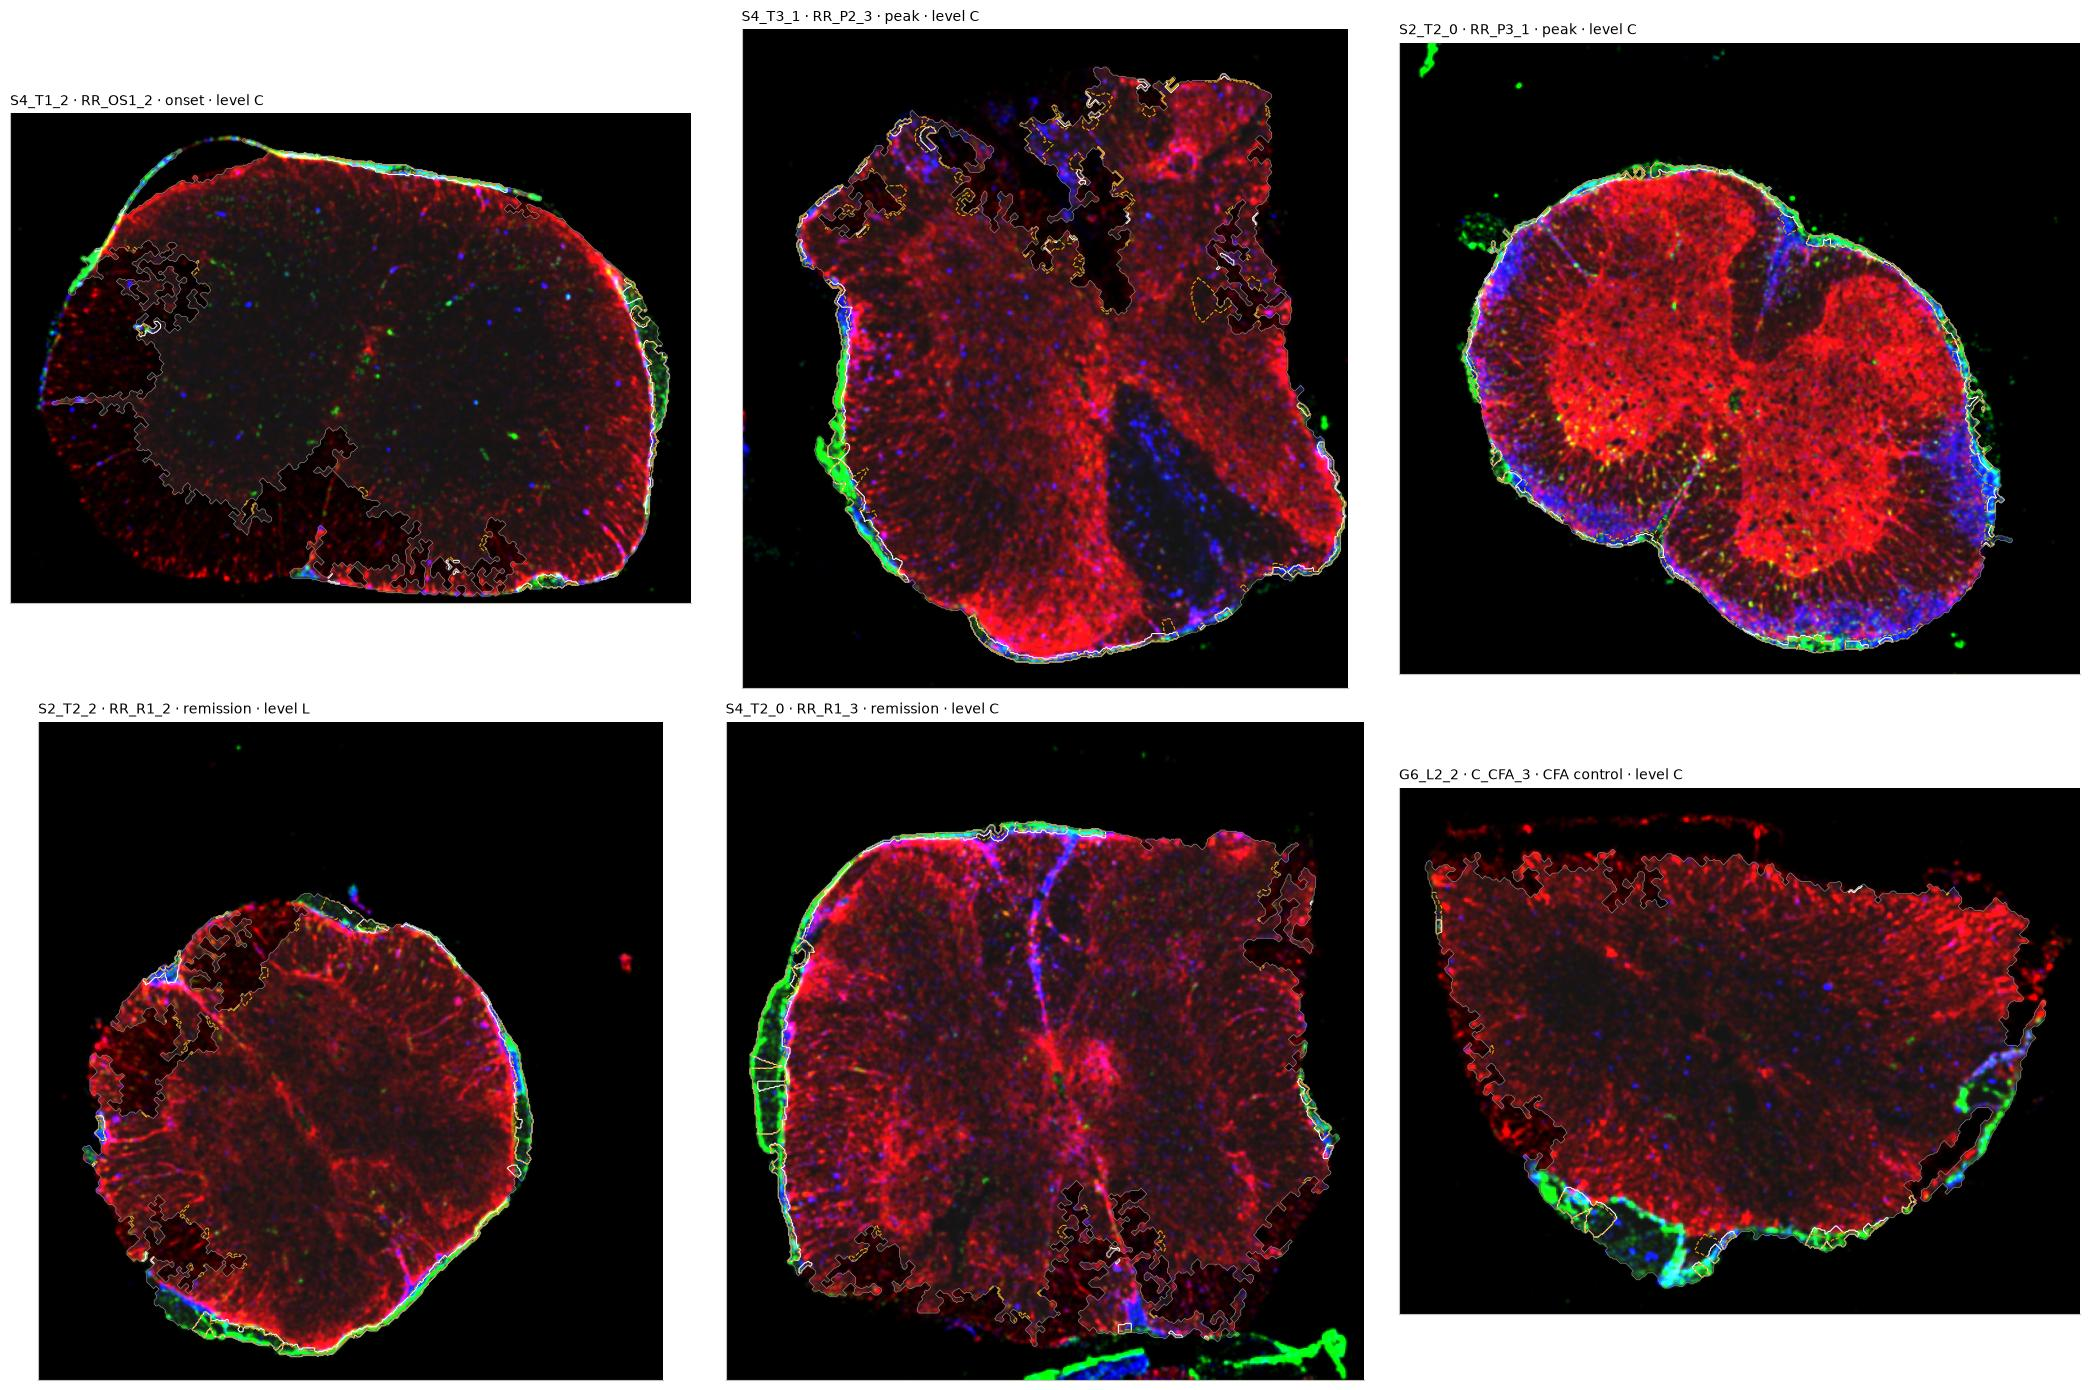

In [4]:
cells_atlas = pd.read_parquet(WORK / "atlas_cells.parquet").rename(columns={"meta_sample_id": "section"})
TWIN = {a: f"RR_{a}" for a in ["OS1_2", "P2_3", "P3_1", "R1_2", "R1_3"]}
ex = (sh[sh.animal.isin(TWIN.values())].sort_values(["animal", "spinal_level"]).groupby("animal").head(1).section.tolist()
      + sh[sh.group == "CFA control"].section.iloc[[3]].tolist())
fig, axes = plt.subplots(2, 3, figsize=(21, 14))
for ax, s in zip(axes.ravel(), ex):
    r = sh[sh.section == s].iloc[0]
    c = cells_atlas[cells_atlas.section == s]
    rgb, men, tis, ext = X.section_view("outputs/xenium_rasters", r, c, pia)
    men_g = X.section_view("outputs/xenium_rasters", r, c, pia, col="pia_glia_um")[1]
    ax.imshow(rgb, extent=ext)
    ax.contour(men, levels=[0.5], colors="white", linewidths=0.8, extent=ext, origin="upper")
    ax.contour(men_g, levels=[0.5], colors="#eda100", linewidths=0.8, linestyles="--", extent=ext, origin="upper")
    ax.contour(tis, levels=[0.5], colors="#898781", linewidths=0.5, extent=ext, origin="upper")
    ax.set_title(f"{s} · {r.animal} · {r.group} · level {r.spinal_level}", loc="left", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## How deep is the pia? (per 50 µm stretch)

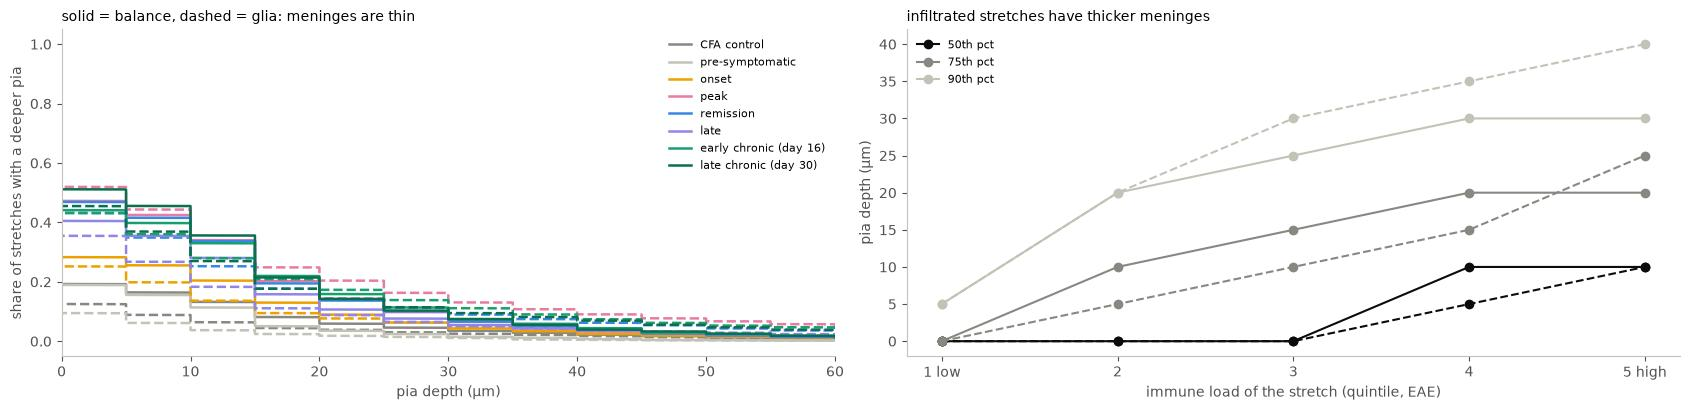

pia_depth_um                        pia_glia_um                       
                              count  mean  50%   75%   90%       count  mean  50%   75%   90%
group                                                                                        
CFA control                  3728.0   4.2  0.0   0.0  15.0      3728.0   2.7  0.0   0.0   5.0
pre-symptomatic              1635.0   3.1  0.0   0.0  15.0      1635.0   1.4  0.0   0.0   0.0
onset                        4282.0   6.1  0.0  10.0  20.0      4282.0   5.7  0.0   5.0  15.0
peak                         8560.0   9.6  0.0  15.0  25.0      8560.0  14.0  5.0  15.0  40.0
remission                    4992.0   9.6  0.0  15.0  30.0      4992.0   9.9  0.0  15.0  30.0
late                         2395.0   8.1  0.0  15.0  25.0      2395.0   6.8  0.0  10.0  20.0
early chronic (day 16)       1969.0   9.9  0.0  15.0  30.0      1969.0  11.2  0.0  15.0  35.0
late chronic (day 30)        2215.0  10.4  5.0  15.0  30.0      2215.0  10.5  0.0  15.0  30.0

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
ax = axes[0]
for g in PH:
    for col, ls in (("pia_depth_um", "-"), ("pia_glia_um", "--")):
        v = np.sort(pia[pia.group == g][col])
        ax.plot(v, 1 - np.arange(len(v)) / len(v), color=PCOL[g], lw=1.8, ls=ls, label=g if ls == "-" else None)
ax.set_xlim(0, 60); ax.set_xlabel("pia depth (µm)"); ax.set_ylabel("share of stretches with a deeper pia")
ax.legend(fontsize=8, frameon=False); ax.set_title("solid = balance, dashed = glia: meninges are thin", loc="left", fontsize=10)
ax = axes[1]
e = pia[pia.group != "CFA control"].copy()
e["load"] = pd.qcut(e.immune_frac_0_80.rank(method="first"), 5, labels=["1 low", "2", "3", "4", "5 high"])
for col, ls in (("pia_depth_um", "-"), ("pia_glia_um", "--")):
    t = e.groupby("load", observed=True)[col].describe(percentiles=[.5, .75, .9])
    for q, c in (("50%", "#0b0b0b"), ("75%", "#898781"), ("90%", "#c3c2b7")):
        ax.plot(t.index.astype(str), t[q], marker="o", color=c, ls=ls, label=f"{q[:-1]}th pct" if ls == "-" else None)
ax.set_xlabel("immune load of the stretch (quintile, EAE)"); ax.set_ylabel("pia depth (µm)"); ax.legend(fontsize=8, frameon=False)
ax.set_title("infiltrated stretches have thicker meninges", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
pd.concat({c: pia.groupby("group")[c].describe(percentiles=[.5, .75, .9])[["count", "mean", "50%", "75%", "90%"]]
           for c in ("pia_depth_um", "pia_glia_um")}, axis=1).reindex(PH).round(1)

## Are immune cells near the surface meningeal or subpial?

Share of atlas cells **above** the pia of their stretch, by depth; solid = balance, dashed = glia. Meningeal
fibroblasts are the method's control: ~87 % of them at 0–10 µm land above the pia (5 µm rings and cell
positions set a floor of ~13 % misplacement).

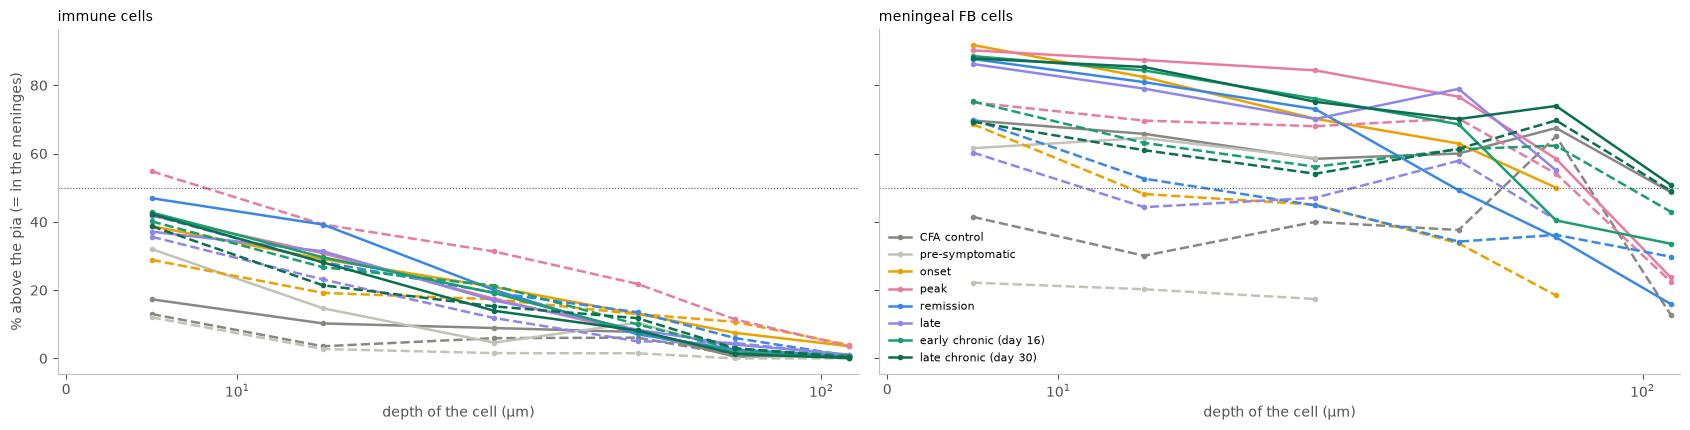

group                 CFA control  pre-symptomatic  onset  peak  remission  late  early chronic (day 16)  late chronic (day 30)
definition depth_bin                                                                                                           
balance    (0, 10]           17.0             32.0   39.0  42.0       47.0  37.0                    43.0                   42.0
           (10, 20]          10.0             15.0   29.0  31.0       39.0  31.0                    30.0                   28.0
           (20, 30]           9.0              5.0   21.0  17.0       20.0  17.0                    19.0                   14.0
           (30, 50]           8.0             10.0   13.0   7.0        7.0   8.0                     8.0                    8.0
           (50, 80]           0.0              2.0    7.0   2.0        3.0   4.0                     2.0                    1.0
           (80, 150]          1.0              0.0    4.0   0.0        1.0   1.0                     0.0                    0.0
glia       (0, 10]           13.0             12.0   29.0  55.0       42.0  36.0                    40.0                   39.0
           (10, 20]           4.0              3.0   19.0  39.0       28.0  23.0                    27.0                   21.0
           (20, 30]           6.0              2.0   17.0  31.0       19.0  12.0                    21.0                   15.0
           (30, 50]           6.0              1.0   13.0  22.0       13.0   5.0                    10.0                   12.0
           (50, 80]           1.0              0.0   11.0  11.0        6.0   5.0                     3.0                    3.0
           (80, 150]          1.0              0.0    4.0   3.0        1.0   1.0                     1.0                    0.0

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4), sharey=True)
for ax, cls in zip(axes, ["immune", "meningeal FB"]):
    for g in PH:
        for dfn, ls in (("balance", "-"), ("glia", "--")):
            d = ab[(ab.definition == dfn) & (ab.cell_class == cls) & (ab.group == g) & ab.depth_bin.isin(BINS)]
            d = d.assign(x=d.depth_bin.map(MID)).sort_values("x")
            d = d[d.cells >= 30]
            ax.plot(d.x, 100 * d.above_pia, color=PCOL[g], lw=1.8, ls=ls, marker="o", ms=3,
                    label=g if dfn == "balance" else None)
    ax.axhline(50, color="#52514e", lw=0.8, ls=":"); ax.set_xscale("symlog", linthresh=30)
    ax.set_xlabel("depth of the cell (µm)"); ax.set_title(f"{cls} cells", loc="left", fontsize=10)
axes[0].set_ylabel("% above the pia (= in the meninges)"); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
t = (ab[(ab.cell_class == "immune") & ab.depth_bin.isin(BINS)]
     .pivot_table(index=["definition", "depth_bin"], columns="group", values="above_pia"))
(100 * t.reindex(columns=PH)).reindex(BINS, level=1).round(0)

### Sensitivity: the balance definition's minimum meningeal level

The fibroblast control hardly moves with the threshold, so it cannot pick it; the immune shares at 0–20 µm do
move (the default is 0.1). The conclusion below 20–30 µm does not depend on it.

In [7]:
sens = pd.read_csv(OUT / "sensitivity_min_meningeal.csv")
(100 * sens.set_index(["cells", "min_meningeal"])[BINS]).round(0)

,,"(0, 10]","(10, 20]","(20, 30]","(30, 50]","(50, 80]","(80, 150]"
cells,min_meningeal,,,,,,
meningeal FB,0.00,87.0,82.0,75.0,70.0,60.0,37.0
immune (EAE),0.00,48.0,40.0,27.0,14.0,5.0,1.0
meningeal FB,0.05,87.0,82.0,75.0,69.0,58.0,35.0
immune (EAE),0.05,45.0,36.0,21.0,10.0,3.0,1.0
meningeal FB,0.10,87.0,82.0,75.0,67.0,55.0,32.0
immune (EAE),0.10,42.0,32.0,18.0,8.0,2.0,1.0
meningeal FB,0.20,86.0,81.0,72.0,65.0,51.0,30.0
immune (EAE),0.20,36.0,26.0,13.0,5.0,2.0,0.0
meningeal FB,0.30,85.0,80.0,70.0,62.0,48.0,27.0


## Per section (immune cells, balance definition; sections with ≥ 20 immune cells in the bin)

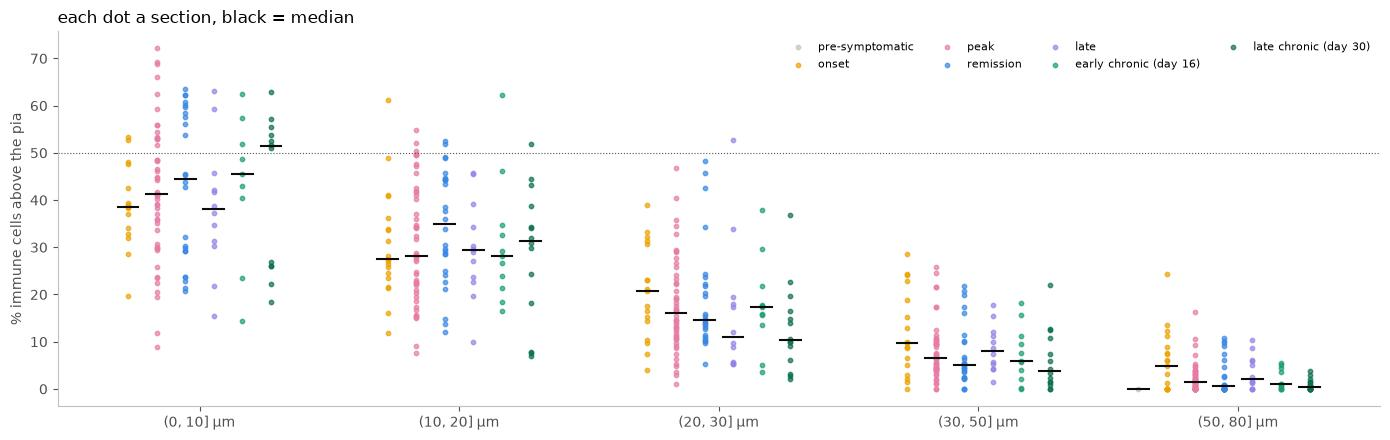

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.5))
b_ = abs_[abs_.definition == "balance"]
for i, b in enumerate(BINS[:5]):
    for j, g in enumerate(EAE):
        v = b_[(b_.depth_bin == b) & (b_.group == g) & (b_.cells >= 20)].above_pia * 100
        x = i + (j - len(EAE) / 2) * 0.11
        ax.scatter(np.full(len(v), x), v, s=10, color=PCOL[g], alpha=0.7, label=g if i == 0 else None)
        if len(v):
            ax.plot([x - 0.04, x + 0.04], [v.median()] * 2, color="#0b0b0b", lw=1.5)
ax.axhline(50, color="#52514e", lw=0.8, ls=":")
ax.set_xticks(range(5), [f"{b} µm" for b in BINS[:5]]); ax.set_ylabel("% immune cells above the pia")
ax.legend(fontsize=8, frameon=False, ncol=4); ax.set_title("each dot a section, black = median", loc="left")
plt.tight_layout(); plt.show()

## What it means for our rule

Our rule calls the outer 10 µm meninges and extends the meninges into compact infiltrate connected to it, down to
80 µm. Below: how deep our rule's Pu.1⁺ meninges cells are, and – applying the Xenium share of immune cells
above the pia in the **same animal** – how many of them would be subpial (range over the two definitions).

**Assumption to confirm:** our animals OS1_2, P2_3, P3_1, R1_2 and R1_3 are the RRMAP2 animals RR_OS1_2,
RR_P2_3, RR_P3_1, RR_R1_2 and RR_R1_3 (same names, same C/T/L levels). CFA_L2 has no match and uses the pooled
CFA controls. Xenium sections of an animal are pooled over levels (few immune cells per bin otherwise); bins
with < 20 Xenium immune cells fall back to the animal's phase.

In [9]:
rows = []
for r in runs:
    m = r.cells[(r.cells.section_id > 0) & (r.cells.surface_tier.astype(str) == "meninges") & r.cells.pu1_pos]
    m = m.assign(animal=m.section_name.astype(str).str.rsplit("_", n=1).str[0],
                 depth_bin=pd.cut(m.depth_um, [0, 10, 20, 30, 50, 80, 150], labels=BINS, include_lowest=True).astype(str))
    rows.append(m.groupby(["animal", "depth_bin"]).size().rename("pu1_meninges_cells").reset_index())
ours_t = pd.concat(rows).groupby(["animal", "depth_bin"], as_index=False).pu1_meninges_cells.sum()
ours_t = ours_t[ours_t.depth_bin.isin(BINS)]
grp_of = sh.drop_duplicates("animal").set_index("animal").group
phase_rate = (pd.read_csv(OUT / "above_pia_by_depth.csv").query("cell_class == 'immune'")
              .set_index(["definition", "group", "depth_bin"]).above_pia)
est = []
for dfn in ("balance", "glia"):
    a = aba[(aba.definition == dfn)].set_index(["animal", "depth_bin"])
    t = ours_t.copy()
    t["xenium_animal"] = t.animal.map(TWIN)
    t["grp"] = t.xenium_animal.map(grp_of).fillna("CFA control")

    def rate(row):
        k = (row.xenium_animal, row.depth_bin)
        if isinstance(row.xenium_animal, str) and k in a.index and a.loc[k, "cells"] >= 20:
            return a.loc[k, "above_pia"]
        return phase_rate.get((dfn, row.grp, row.depth_bin), np.nan)
    t["xenium_above"] = t.apply(rate, axis=1)
    t["expected_subpial"] = t.pu1_meninges_cells * (1 - t.xenium_above)
    est.append(t.assign(definition=dfn))
est = pd.concat(est)
tab = est.pivot_table(index="depth_bin", columns="definition", values="expected_subpial", aggfunc="sum").reindex(BINS)
tab.insert(0, "pu1_meninges_cells", est[est.definition == "balance"].groupby("depth_bin").pu1_meninges_cells.sum())
display(tab.round(0))
tot = tab.pu1_meninges_cells.sum()
for dfn in ("balance", "glia"):
    print(f"{dfn:8s}: of {tot:,.0f} Pu.1+ cells our rule calls meninges, expected subpial {tab[dfn].sum():,.0f} "
          f"({100 * tab[dfn].sum() / tot:.0f} %); deeper than 20 µm: {tab.loc[BINS[2:], dfn].sum():,.0f} "
          f"of {tab.loc[BINS[2:], 'pu1_meninges_cells'].sum():,.0f}")
display((100 * est.pivot_table(index=["definition", "animal"], columns="depth_bin", values="xenium_above")
         .reindex(columns=BINS)).round(0))

definition,pu1_meninges_cells,balance,glia
depth_bin,,,
"(0, 10]",3281,1881.0,1631.0
"(10, 20]",1570,974.0,1014.0
"(20, 30]",937,694.0,680.0
"(30, 50]",759,711.0,665.0
"(50, 80]",360,353.0,334.0
"(80, 150]",34,34.0,34.0


balance : of 6,941 Pu.1+ cells our rule calls meninges, expected subpial 4,647 (67 %); deeper than 20 µm: 1,792 of 2,090
glia    : of 6,941 Pu.1+ cells our rule calls meninges, expected subpial 4,357 (63 %); deeper than 20 µm: 1,712 of 2,090


depth_bin          (0, 10]  (10, 20]  (20, 30]  (30, 50]  (50, 80]  (80, 150]
definition animal                                                            
balance    CFA_L2     17.0      10.0       9.0       8.0       0.0        1.0
           OS1_2      29.0      19.0      12.0       4.0       0.0        NaN
           P2_3       32.0      27.0      22.0       8.0       2.0        NaN
           P3_1       63.0      41.0      25.0       8.0       2.0        NaN
           R1_2       52.0      48.0      30.0       5.0       2.0        0.0
           R1_3       33.0      39.0      31.0      12.0       NaN        NaN
glia       CFA_L2     13.0       4.0       6.0       6.0       1.0        1.0
           OS1_2      16.0      10.0       2.0       4.0       0.0        NaN
           P2_3       59.0      38.0      32.0      18.0      11.0        NaN
           P3_1       65.0      46.0      36.0      19.0       9.0        NaN
           R1_2       54.0      32.0      24.0       7.0       4.0        0.0
           R1_3       36.0      30.0      15.0       7.0       NaN        NaN

## Reading

* **The meninges are thin, and the genes find them.** Meningeal fibroblast genes sit in the outer 5–15 µm and in
  most stretches the pia lies within 0–15 µm of the edge (90th percentile ~15–25 µm). Infiltrated stretches
  have thicker meninges, so swelling is real but modest in µm terms.
* **Most immune cells near the surface are subpial, and almost all deeper than ~20–30 µm are.** Both
  definitions – with opposite biases – agree: in EAE ~30–55 % of immune cells at 0–10 µm are above the pia,
  ~20–40 % at 10–20 µm, ~10–30 % at 20–30 µm and ≤ ~20 % beyond 30 µm. CFA controls have few immune cells and
  even fewer meningeal ones.
* **For our rule:** extending the meninges into compact infiltrate down to 80 µm takes in mostly subpial lesion –
  the table above estimates how many of our rule's Pu.1⁺ meninges cells that is. A cap of ~20 µm (or no infiltrate
  extension beyond the outer layer) would match the genes better; even the outer 10 µm holds a lot of subpial
  infiltrate in EAE.
* **It explains notebook 13:** meninges and lesion genuinely interleave in the outer 10–30 µm, so a model trained
  on "outer ≤ 10 µm = meninges" learns infiltrate, and no image feature separates them.
* **Which definition to trust:** by the fibroblast control, *balance* (≈ 87 % of meningeal fibroblasts at 0–10 µm
  above its pia) is clearly better than *glia* (60–75 % in EAE, ~40 % in controls, where the glia limitans
  sits right at the edge); glia is kept as the bracket with the opposite bias. Expected subpial share of our
  rule's Pu.1⁺ meninges cells: ~63–67 % overall, ~82–86 % of those deeper than 20 µm.
* **Caveats.** Different cells, segmentation and tissue mask than our images: the depth scales are not
  calibrated (treat µm values as ±5–10 µm). The pia is resolved in 5 µm rings; ~30 % of stretches (tears,
  flaps, oblique cuts) have none. Low-density patches inside some sections (dark in the maps) are cut out of
  the tissue mask and count as edge. The Xenium sections of "our" animals are probably not the same sections
  (assumption above).